# Marketing Campaign Performance and Customer Behavior Analysis

## Problem Statement

In today's competitive business environment, understanding customer behavior and evaluating marketing campaign effectiveness are essential for making better business decisions. Businesses collect large amounts of customer data, but identifying meaningful patterns related to customer demographics, purchasing behavior, product preferences, and campaign responses can be challenging.

## Objective

The objective of this project is to analyze customer marketing data using Python to identify spending patterns, understand preferred shopping channels, evaluate marketing campaign acceptance rates, and compare the purchasing behavior of customers who accepted a marketing campaign with those who did not. The analysis aims to generate meaningful business insights that can help improve customer engagement and marketing strategies.

## Research Question

Do customers who accept the latest marketing campaign spend significantly more than customers who do not accept it?


## Importing Libraries

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## Loading the dataset

In [84]:
df = pd.read_csv("../data/raw/marketing_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
## Displays the first 5 rows of a DataFrame by default.

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,6,1,0,0,0,0,0,1,0,Spain
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,7,5,0,0,0,0,1,1,0,Canada
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,5,2,0,0,0,0,0,0,0,USA
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,2,7,0,0,0,0,0,0,0,Australia
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,2,7,1,0,0,0,0,1,0,Spain


In [ ]:
## df.shape returns the total number of rows and columns.

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2240
Number of Columns: 28


In [ ]:
## Identify all columns available for analysis.

print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country']


In [ ]:
## Shows datatype of each column.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4    Income              2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [ ]:
## Remove extra spaces from column names

df.columns = df.columns.str.strip()

## Display updated column names
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country']


In [ ]:
## Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Income    24
dtype: int64


In [ ]:
## Percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_report[missing_report['Missing Values'] > 0])

        Missing Values  Missing Percentage
Income              24            1.071429


In [ ]:
## Count duplicate rows

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [ ]:
## Check duplicate customer IDs.

print("Duplicate Customer IDs:", df['ID'].duplicated().sum())

Duplicate Customer IDs: 0


In [ ]:
## Datatype conversion of "Dt_Customer" column from str to datetime[us].

df['Dt_Customer'] = pd.to_datetime(
    df['Dt_Customer'],
    errors='coerce'
)

print(df['Dt_Customer'].dtype)

datetime64[us]


In [ ]:
## Check invalid dates.

print("Invalid Dates:", df['Dt_Customer'].isnull().sum())

Invalid Dates: 0


In [ ]:
## Statistical summary of numerical columns.

df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142,49.109375,303.935714,26.302232,166.950000,...,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.149107,0.009375
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,...,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.356274,0.096391


In [ ]:
## ## The dataset contains 3 suspicious records. Based on the 2014 context, these customers would be approximately 114–121 years old.

print("Minimum Birth Year:", df['Year_Birth'].min())
print("Maximum Birth Year:", df['Year_Birth'].max())

print("\nCustomers born before 1940:")
print(df[df['Year_Birth'] < 1940][['ID', 'Year_Birth']])

Minimum Birth Year: 1893
Maximum Birth Year: 1996

Customers born before 1940:
         ID  Year_Birth
513   11004        1893
827    1150        1899
2233   7829        1900


In [ ]:
## ## The dataset contains 8 customers with income above 150,000. Only 666,666 is considered an invalid value and marked as missing, while other high-income values are retained.

print("Minimum Income:", df['Income'].min())
print("Maximum Income:", df['Income'].max())

print("\nCustomers with Income above 150000:")
print(df[df['Income'] > 150000][['ID', 'Income']])

Minimum Income: 1730.0
Maximum Income: 666666.0

Customers with Income above 150000:
         ID    Income
325    4931  157146.0
497    1501  160803.0
527    9432  666666.0
731    1503  162397.0
853    5336  157733.0
1826   5555  153924.0
1925  11181  156924.0
2204   8475  157243.0


In [ ]:
## Various categories in Education and Marital status column and their frequency.

print("Education Categories:")
print(df['Education'].value_counts())

print("\nMarital Status Categories:")
print(df['Marital_Status'].value_counts())

Education Categories:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Marital Status Categories:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64


In [ ]:
## Campaign response distribution

print(df['Response'].value_counts())

Response
0    1906
1     334
Name: count, dtype: int64


In [ ]:
## Percentage of campaign response distribution.
print(df['Response'].value_counts(normalize=True) * 100)

Response
0    85.089286
1    14.910714
Name: proportion, dtype: float64


## Data Cleaning

In [ ]:
## copy() creates a separate DataFrame. The original dataset remains unchanged.

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Clean Dataset Shape:", df_clean.shape)

Original Dataset Shape: (2240, 28)
Clean Dataset Shape: (2240, 28)


In [ ]:
## Calculate approximate customer age
df_clean['Age'] = 2014 - df_clean['Year_Birth']

## Mark ages above 100 as invalid for age analysis
df_clean.loc[df_clean['Age'] > 100, 'Age'] = np.nan

print("Missing Age Values:", df_clean['Age'].isnull().sum())

Missing Age Values: 3


In [ ]:
## Treat extremely suspicious income as missing
df_clean.loc[df_clean['Income'] == 666666, 'Income'] = np.nan

print("Missing Income After Outlier Treatment:",
      df_clean['Income'].isnull().sum())

Missing Income After Outlier Treatment: 25


In [ ]:
## Calculate median income
## The median is less affected by extreme values; therefore, median imputation is a reasonable choice for handling missing income values.
income_median = df_clean['Income'].median()

print("Median Income:", income_median)

## Fill missing values
df_clean['Income'] = df_clean['Income'].fillna(income_median)

print("Missing Income After Cleaning:",
      df_clean['Income'].isnull().sum())

Median Income: 51373.0
Missing Income After Cleaning: 0


In [ ]:
## Group unusual categories into Other
df_clean['Marital_Status'] = df_clean['Marital_Status'].replace({
    'Alone': 'Other',
    'YOLO': 'Other',
    'Absurd': 'Other'
})

print(df_clean['Marital_Status'].value_counts())

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Other         7
Name: count, dtype: int64


In [ ]:
## Final Verification before analysis begin.

print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Final Dataset Shape: (2240, 29)

Missing Values:
Age    3
dtype: int64

Duplicate Rows: 0

Data Types:
ID                              int64
Year_Birth                      int64
Education                         str
Marital_Status                    str
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[us]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1           

In [ ]:
## Save clean file in csv format.

df_clean.to_csv(
    "../data/processed/marketing_campaign_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
## Calculate Total Spending: We are adding the spending across all six product categories for each customer.

spending_columns = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df_clean['Total_Spending'] = df_clean[spending_columns].sum(axis=1)

print(df_clean[['ID', 'Total_Spending']].head())

      ID  Total_Spending
0   1826            1190
1      1             577
2  10476             251
3   1386              11
4   5371              91


In [ ]:
## Calculate Total Purchases: We are adding the number of purchases made through deals, websites, catalog, physical store.

purchase_columns = [
    'NumDealsPurchases',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df_clean['Total_Purchases'] = df_clean[purchase_columns].sum(axis=1)

print(df_clean[['ID', 'Total_Purchases']].head())

      ID  Total_Purchases
0   1826               15
1      1               18
2  10476               11
3   1386                4
4   5371                8


In [ ]:
## Verify the new columns

print("New Dataset Shape:", df_clean.shape)

print("\nTotal Spending Summary:")
print(df_clean['Total_Spending'].describe())

print("\nTotal Purchases Summary:")
print(df_clean['Total_Purchases'].describe())

New Dataset Shape: (2240, 31)

Total Spending Summary:
count    2240.000000
mean      605.798214
std       602.249288
min         5.000000
25%        68.750000
50%       396.000000
75%      1045.500000
max      2525.000000
Name: Total_Spending, dtype: float64

Total Purchases Summary:
count    2240.000000
mean       14.862054
std         7.677173
min         0.000000
25%         8.000000
50%        15.000000
75%        21.000000
max        44.000000
Name: Total_Purchases, dtype: float64


## Exploratory Data Analysis (EDA)

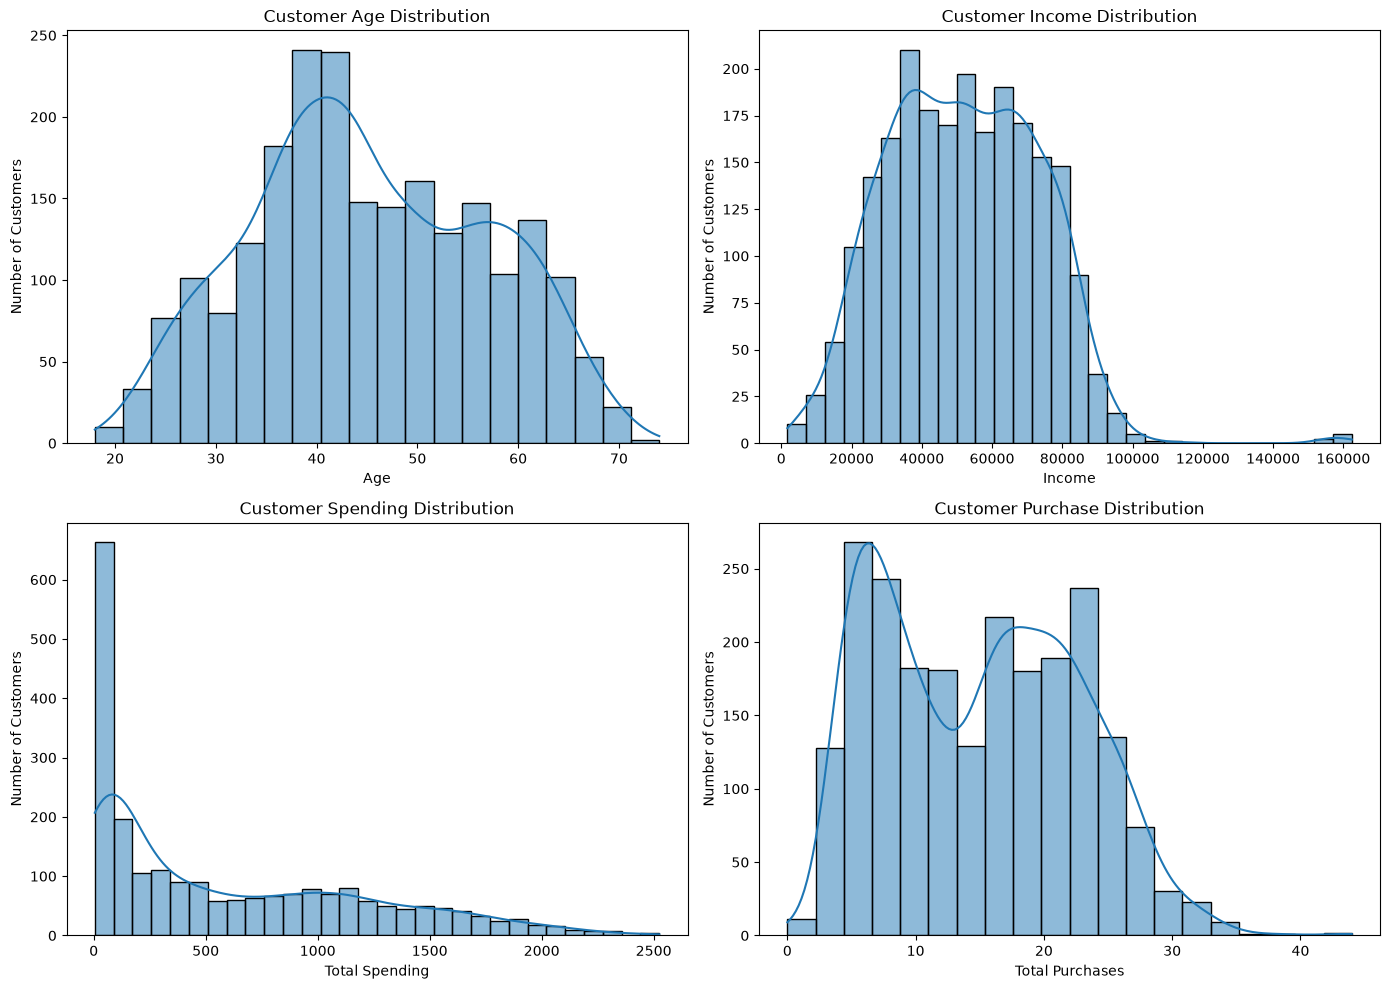

In [ ]:
## Create a histogram as it helps us understand how values are distributed.

plt.figure(figsize=(14, 10))

# Age Distribution
plt.subplot(2, 2, 1)
sns.histplot(df_clean['Age'], bins=20, kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

# Income Distribution
plt.subplot(2, 2, 2)
sns.histplot(df_clean['Income'], bins=30, kde=True)
plt.title('Customer Income Distribution')
plt.xlabel('Income')
plt.ylabel('Number of Customers')

# Total Spending Distribution
plt.subplot(2, 2, 3)
sns.histplot(df_clean['Total_Spending'], bins=30, kde=True)
plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

# Total Purchases Distribution
plt.subplot(2, 2, 4)
sns.histplot(df_clean['Total_Purchases'], bins=20, kde=True)
plt.title('Customer Purchase Distribution')
plt.xlabel('Total Purchases')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [ ]:
## Check Skewness: Customer spending is more positively skewed than age, income, and purchase distributions,
##  indicating that a few customers contribute significantly higher spending than others.

columns_to_check = [
    'Age',
    'Income',
    'Total_Spending',
    'Total_Purchases'
]

print(df_clean[columns_to_check].skew())

Age                0.093266
Income             0.350231
Total_Spending     0.860841
Total_Purchases    0.252111
dtype: float64


In [ ]:
## Distribution analysis

columns = ['Age', 'Income', 'Total_Spending', 'Total_Purchases']

for col in columns:
    print("\n", "=" * 40)
    print("Column:", col)
    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())
    print("Mean:", round(df_clean[col].mean(), 2))
    print("Median:", round(df_clean[col].median(), 2))
    print("Skewness:", round(df_clean[col].skew(), 3))


Column: Age
Minimum: 18.0
Maximum: 74.0
Mean: 45.1
Median: 44.0
Skewness: 0.093

Column: Income
Minimum: 1730.0
Maximum: 162397.0
Mean: 51963.2
Median: 51373.0
Skewness: 0.35

Column: Total_Spending
Minimum: 5
Maximum: 2525
Mean: 605.8
Median: 396.0
Skewness: 0.861

Column: Total_Purchases
Minimum: 0
Maximum: 44
Mean: 14.86
Median: 15.0
Skewness: 0.252


In [ ]:
## Product category spending

product_spending = df_clean[
    [
        'MntWines',
        'MntFruits',
        'MntMeatProducts',
        'MntFishProducts',
        'MntSweetProducts',
        'MntGoldProds'
    ]
].sum().sort_values(ascending=False)

print("Product Category Spending:")
print(product_spending)

Product Category Spending:
MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64


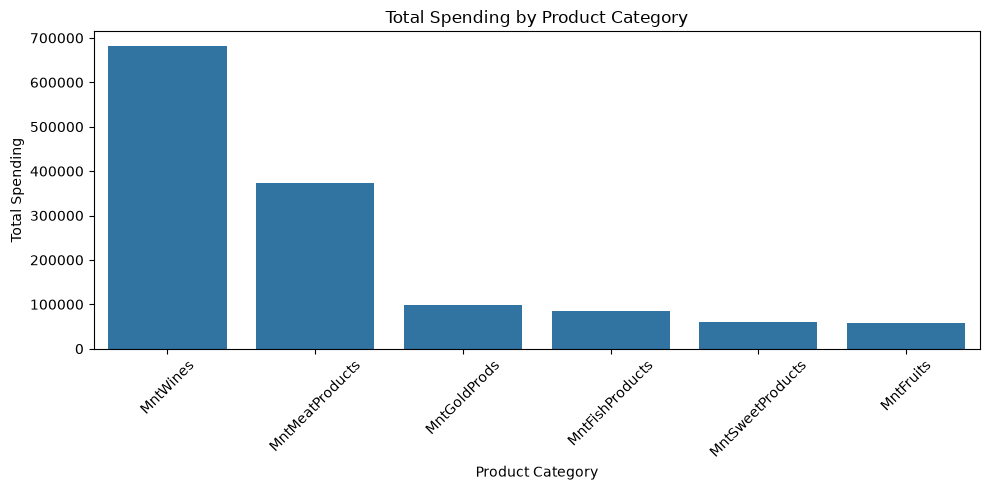

In [ ]:
## Visualization of product category spending.
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_spending.index,
    y=product_spending.values
)

plt.title('Total Spending by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
## Analyze purchase channels

channel_columns = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases',
    'NumDealsPurchases'
]

channel_analysis = df_clean[channel_columns].sum().sort_values(
    ascending=False
)

print("Total Purchases by Channel:")
print(channel_analysis)

print("\nAverage Purchases by Channel:")
print(df_clean[channel_columns].mean().round(2))

Total Purchases by Channel:
NumStorePurchases      12970
NumWebPurchases         9150
NumCatalogPurchases     5963
NumDealsPurchases       5208
dtype: int64

Average Purchases by Channel:
NumWebPurchases        4.08
NumCatalogPurchases    2.66
NumStorePurchases      5.79
NumDealsPurchases      2.33
dtype: float64


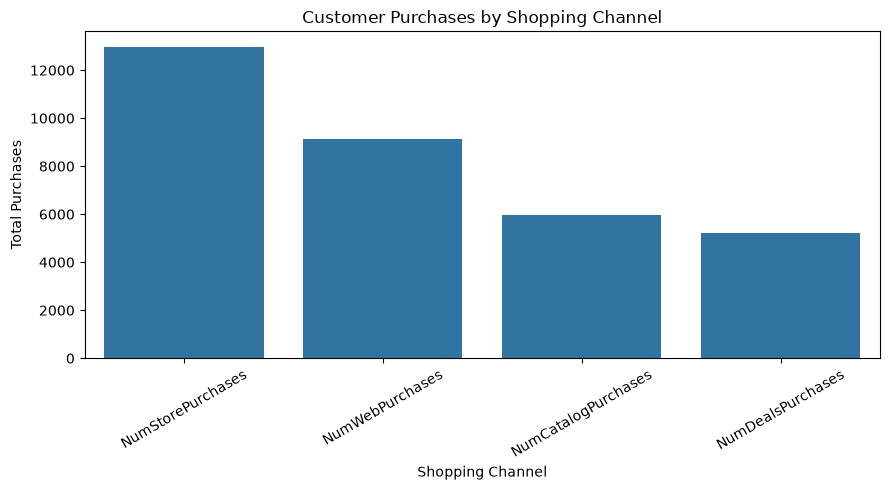

In [ ]:
## Visualize purchase channels

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_analysis.index,
    y=channel_analysis.values
)

plt.title('Customer Purchases by Shopping Channel')
plt.xlabel('Shopping Channel')
plt.ylabel('Total Purchases')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
## Campaign performance analysis

campaign_columns = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5',
    'Response'
]

print("CAMPAIGN ACCEPTANCE")
print(df_clean[campaign_columns].sum())

print("\nACCEPTANCE PERCENTAGE")
print((df_clean[campaign_columns].mean() * 100).round(2))

print("\nCUSTOMER RESPONSE")
print(df_clean['Response'].value_counts())

CAMPAIGN ACCEPTANCE
AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    163
Response        334
dtype: int64

ACCEPTANCE PERCENTAGE
AcceptedCmp1     6.43
AcceptedCmp2     1.34
AcceptedCmp3     7.28
AcceptedCmp4     7.46
AcceptedCmp5     7.28
Response        14.91
dtype: float64

CUSTOMER RESPONSE
Response
0    1906
1     334
Name: count, dtype: int64


### Hypothesis
- H₀ (Null): Campaign accept karne wale customers ka average spending, non-accepting customers se higher nahi hai.
- H₁ (Alternative): Campaign accept karne wale customers ka average spending, non-accepting customers se higher hai.

In [ ]:
from scipy.stats import ttest_ind

## Separate customers into two groups

responders = df_clean[df_clean['Response'] == 1]['Total_Spending']
non_responders = df_clean[df_clean['Response'] == 0]['Total_Spending']

## Calculate average spending

print("Average Spending - Responders:", round(responders.mean(), 2))
print("Average Spending - Non-Responders:", round(non_responders.mean(), 2))

## Welch's independent t-test

t_stat, p_value = ttest_ind(
    responders,
    non_responders,
    equal_var=False,
    alternative='greater'
)

print("\nT-Statistic:", round(t_stat, 4))
print("P-Value:", p_value)

## Conclusion

if p_value < 0.05:
    print("\nReject Null Hypothesis (H0)")
    print("Campaign responders spend significantly more.")
else:
    print("\nFail to Reject Null Hypothesis (H0)")
    print("There is insufficient evidence that responders spend more.")

Average Spending - Responders: 987.39
Average Spending - Non-Responders: 538.93

T-Statistic: 10.8503
P-Value: 1.5016545633714086e-24

Reject Null Hypothesis (H0)
Campaign responders spend significantly more.


In [ ]:
## Customer segmentation by age

df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)

age_analysis = df_clean.groupby(
    'Age_Group', observed=False
).agg(
    Customers=('ID', 'count'),
    Average_Income=('Income', 'mean'),
    Average_Spending=('Total_Spending', 'mean'),
    Campaign_Responses=('Response', 'sum')
).round(2)

age_analysis['Response_Rate'] = (
    age_analysis['Campaign_Responses'] /
    age_analysis['Customers'] * 100
).round(2)

print(age_analysis)

           Customers  Average_Income  Average_Spending  Campaign_Responses  \
Age_Group                                                                    
18-25             91        49473.90            697.03                  15   
26-35            386        46057.49            532.70                  72   
36-45            758        49622.22            536.32                 109   
46-55            486        54254.40            626.98                  59   
56-65            439        56865.45            684.99                  64   
65+               77        64827.06            961.57                  15   

           Response_Rate  
Age_Group                 
18-25              16.48  
26-35              18.65  
36-45              14.38  
46-55              12.14  
56-65              14.58  
65+                19.48  


In [ ]:
## Campaign response by education

education_analysis = df_clean.groupby('Education').agg(
    Customers=('ID', 'count'),
    Responses=('Response', 'sum'),
    Average_Spending=('Total_Spending', 'mean')
).round(2)

education_analysis['Response_Rate'] = (
    education_analysis['Responses'] /
    education_analysis['Customers'] * 100
).round(2)

print(education_analysis.sort_values('Response_Rate', ascending=False))

            Customers  Responses  Average_Spending  Response_Rate
Education                                                        
PhD               486        101            672.41          20.78
Master            370         57            611.78          15.41
Graduation       1127        152            619.90          13.49
2n Cycle          203         22            496.53          10.84
Basic              54          2             81.80           3.70


In [ ]:
## Save final analysis dataset

df_clean.to_csv(
    "../data/processed/marketing_campaign_final.csv",P
    index=False
)

print("Final analysis dataset saved successfully!")
print("Final Shape:", df_clean.shape)

Final analysis dataset saved successfully!
Final Shape: (2240, 32)
